# Week 09 — Cohort (Sample) Size Determination for a Patient–Control Study

How many patients and controls do we actually need to enroll? Too **few** and a real effect is
missed (wasted study, ethical cost of exposing participants for nothing); too **many** and we waste
time, money, and expose more people than necessary. **Sample-size (power) analysis** finds the
smallest cohort that can reliably detect an effect of a pre-specified size.

A **patient–control study** compares an outcome between a *case* group (patients with the condition)
and a *control* group (without it). The outcome can be:
- **continuous** — e.g. a biomarker, ejection fraction, lesion volume → compare **means**;
- **binary** — e.g. responder / non-responder, event / no-event → compare **proportions**.

This notebook explains, step by step:
1. The hypothesis-testing framework and the two error types ($\alpha$, $\beta$) behind power.
2. The four interacting levers: **significance $\alpha$**, **power $1-\beta$**, **effect size**, **variability**.
3. Sample size for comparing **two means** (with a worked biomarker example) and **power curves**.
4. Sample size for comparing **two proportions**.
5. **Unequal allocation** (recruiting more controls than cases).
6. A **Monte-Carlo** check that the formulas deliver the promised power.
7. Practical corrections: **dropout/attrition** and **multiple testing**.

> We derive the formulas from `scipy.stats` normal/t distributions rather than a black-box package, so
> every number is transparent.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 110

## 1. The framework: hypotheses, errors, and power

We test a **null hypothesis** $H_0$ (no difference between patients and controls) against an
**alternative** $H_1$ (a difference of some size exists). Two things can go wrong:

| | $H_0$ true (no real effect) | $H_1$ true (real effect) |
|---|---|---|
| **Test says “significant”** | **Type I error** ($\alpha$) | correct — **power** ($1-\beta$) |
| **Test says “not significant”** | correct | **Type II error** ($\beta$) |

- $\alpha$ = **significance level** = probability of a *false positive* (commonly 0.05).
- $\beta$ = probability of a *false negative* (missing a real effect).
- **Power** $= 1-\beta$ = probability of *detecting* a real effect (commonly 0.80 or 0.90).

The picture below shows the test statistic's distribution under $H_0$ (blue) and under a true effect
$H_1$ (red). The dashed line is the significance threshold; the shaded areas are $\alpha$ and $\beta$.

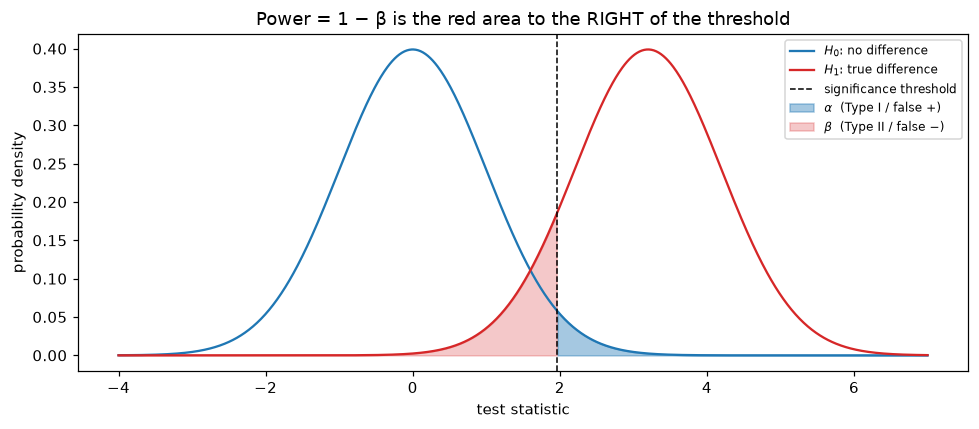

alpha = 0.05,  beta = 0.107,  power = 1 - beta = 0.893


In [2]:
alpha = 0.05
z_crit = stats.norm.ppf(1 - alpha / 2)     # two-sided critical value on the H0 curve
shift = 3.2                                 # separation of H1 from H0 (standardized)

x = np.linspace(-4, 7, 1000)
h0 = stats.norm.pdf(x, 0, 1)
h1 = stats.norm.pdf(x, shift, 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, h0, color="tab:blue", label="$H_0$: no difference")
ax.plot(x, h1, color="tab:red", label="$H_1$: true difference")
ax.axvline(z_crit, color="k", ls="--", lw=1, label="significance threshold")
ax.fill_between(x, h0, where=(x >= z_crit), color="tab:blue", alpha=0.40, label=r"$\alpha$  (Type I / false +)")
ax.fill_between(x, h1, where=(x < z_crit), color="tab:red", alpha=0.25, label=r"$\beta$  (Type II / false −)")
ax.set_xlabel("test statistic"); ax.set_ylabel("probability density")
ax.set_title("Power = 1 − β is the red area to the RIGHT of the threshold")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

beta = stats.norm.cdf(z_crit, shift, 1)
print(f"alpha = {alpha},  beta = {beta:.3f},  power = 1 - beta = {1 - beta:.3f}")

## 2. The four levers and the effect size

Required sample size is driven by **four** quantities. Change any one and the needed $n$ moves:

| Lever | Symbol | Effect on required $n$ |
|---|---|---|
| Significance level | $\alpha$ | smaller $\alpha$ (stricter) → **larger** $n$ |
| Power | $1-\beta$ | higher power → **larger** $n$ |
| Effect size | $\Delta$ / $d$ | smaller effect to detect → **larger** $n$ |
| Variability | $\sigma$ | noisier data → **larger** $n$ |

For **continuous** outcomes we combine the last two into a single standardized **effect size**, the
**Cohen's $d$**:
$$d = \frac{|\mu_\text{patient} - \mu_\text{control}|}{\sigma},$$
the mean difference expressed in standard deviations. Conventional benchmarks are $d=0.2$ (small),
$0.5$ (medium), $0.8$ (large). The smaller the $d$ you want to be able to detect, the more subjects
you need — and $n$ grows with $1/d^2$.

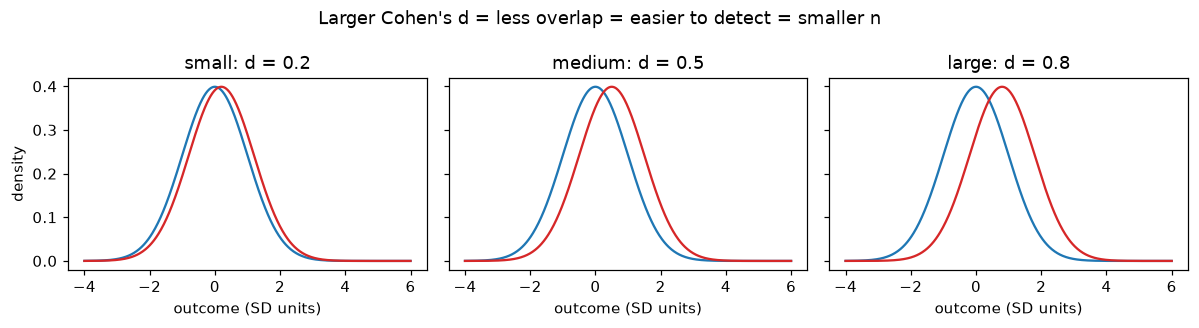

example: patients mean 9.5, controls 8.0, SD 3.0  ->  d = 0.5


In [3]:
def cohens_d(mu1, mu2, sd):
    return abs(mu1 - mu2) / sd

xx = np.linspace(-4, 6, 600)
fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for a, (name, d) in zip(ax, [("small", 0.2), ("medium", 0.5), ("large", 0.8)]):
    a.plot(xx, stats.norm.pdf(xx, 0, 1), color="tab:blue")
    a.plot(xx, stats.norm.pdf(xx, d, 1), color="tab:red")
    a.set_title(f"{name}: d = {d}"); a.set_xlabel("outcome (SD units)")
ax[0].set_ylabel("density")
fig.suptitle("Larger Cohen's d = less overlap = easier to detect = smaller n")
plt.tight_layout(); plt.show()

print("example: patients mean 9.5, controls 8.0, SD 3.0  ->  d =",
      round(cohens_d(9.5, 8.0, 3.0), 3))

## 3. Sample size for comparing two means

For a two-sided two-sample test with **equal groups**, the number per group to detect a mean
difference $\Delta$ with common SD $\sigma$ is
$$n_\text{per group} = \frac{2\,(z_{1-\alpha/2} + z_{1-\beta})^2\,\sigma^2}{\Delta^2}
= \frac{2\,(z_{1-\alpha/2} + z_{1-\beta})^2}{d^2},$$
where $z_{1-\alpha/2}$ and $z_{1-\beta}$ are standard-normal quantiles. The function below also allows
an **allocation ratio** $r = n_\text{control}/n_\text{case}$ (Section 5).

In [4]:
def n_per_group_means(delta, sd, alpha=0.05, power=0.80, ratio=1.0, two_sided=True):
    """Number of CASES needed to detect a mean difference `delta` (common SD `sd`).
    ratio = n_control / n_case; returns (n_case, n_control)."""
    z_a = stats.norm.ppf(1 - alpha / 2) if two_sided else stats.norm.ppf(1 - alpha)
    z_b = stats.norm.ppf(power)
    d = abs(delta) / sd
    n_case = (1 + 1 / ratio) * (z_a + z_b) ** 2 / d ** 2
    n_case = int(np.ceil(n_case))
    return n_case, int(np.ceil(ratio * n_case))

# Worked example: a biomarker averages 8.0 in controls and 9.5 in patients, SD = 3.0.
delta, sd = 1.5, 3.0
n_case, n_ctrl = n_per_group_means(delta, sd, alpha=0.05, power=0.80)
print(f"effect: delta = {delta}  (Cohen's d = {delta/sd:.2f})")
print(f"to achieve 80% power at alpha=0.05 (two-sided):")
print(f"   cases needed    = {n_case}")
print(f"   controls needed = {n_ctrl}")
print(f"   total           = {n_case + n_ctrl}")

# Sensitivity: how n grows as the effect shrinks
print("\nsmaller effects cost more subjects (n per group):")
for dd in [1.5, 1.0, 0.75, 0.5]:
    nc, _ = n_per_group_means(dd, sd)
    print(f"   delta = {dd:>4}  (d={dd/sd:.2f})  ->  {nc:>4} per group")

effect: delta = 1.5  (Cohen's d = 0.50)
to achieve 80% power at alpha=0.05 (two-sided):
   cases needed    = 63
   controls needed = 63
   total           = 126

smaller effects cost more subjects (n per group):
   delta =  1.5  (d=0.50)  ->    63 per group
   delta =  1.0  (d=0.33)  ->   142 per group
   delta = 0.75  (d=0.25)  ->   252 per group
   delta =  0.5  (d=0.17)  ->   566 per group


### Power curves: how power rises with $n$

Fixing $\alpha$ and the effect size, **power** increases with sample size. The curve shows the $n$ at
which each effect size crosses the usual 80% target — small effects need far more subjects.

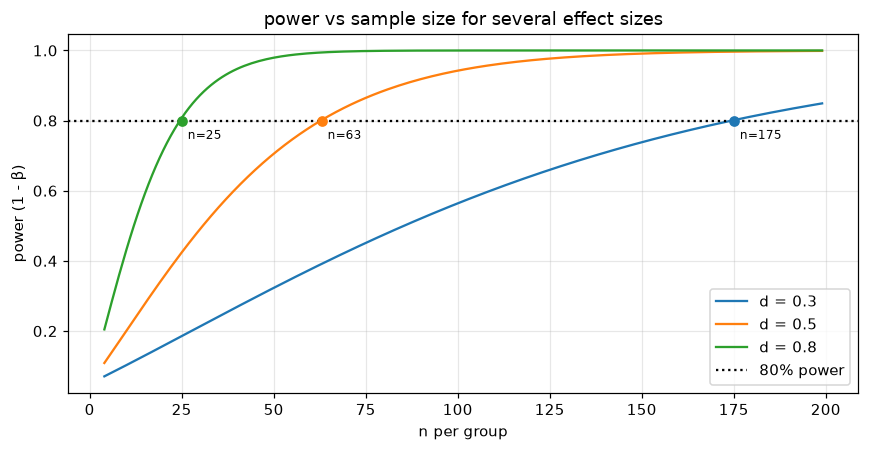

In [5]:
def power_means(n_per_group, d, alpha=0.05, two_sided=True):
    """Power of a two-sample test (equal groups) for standardized effect `d`."""
    z_a = stats.norm.ppf(1 - alpha / 2) if two_sided else stats.norm.ppf(1 - alpha)
    ncp = d * np.sqrt(n_per_group / 2.0)            # noncentrality parameter
    return stats.norm.cdf(ncp - z_a) + stats.norm.cdf(-ncp - z_a)

ns = np.arange(4, 200)
plt.figure(figsize=(8, 4.2))
for d in [0.3, 0.5, 0.8]:
    pw = [power_means(n, d) for n in ns]
    plt.plot(ns, pw, label=f"d = {d}")
    n80 = next(n for n in ns if power_means(n, d) >= 0.80)
    plt.scatter([n80], [0.80], zorder=5)
    plt.annotate(f"n={n80}", (n80, 0.80), textcoords="offset points", xytext=(4, -12), fontsize=8)
plt.axhline(0.80, color="k", ls=":", label="80% power")
plt.xlabel("n per group"); plt.ylabel("power (1 - β)")
plt.title("power vs sample size for several effect sizes")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 4. Sample size for comparing two proportions

When the outcome is **binary** (e.g. responder rate, event rate, prevalence of a finding), we compare
two proportions $p_1$ (patients) and $p_2$ (controls). The per-group size for a two-sided test is
$$n_\text{per group} = \frac{\big(z_{1-\alpha/2}\sqrt{2\bar p(1-\bar p)} +
z_{1-\beta}\sqrt{p_1(1-p_1)+p_2(1-p_2)}\big)^2}{(p_1-p_2)^2},
\qquad \bar p = \tfrac{p_1+p_2}{2}.$$
Detecting a **small** difference in rates, or rates near 50% (maximum variance), requires more
subjects.

In [10]:
def n_per_group_props(p1, p2, alpha=0.05, power=0.80, two_sided=True):
    """Per-group size to detect a difference between proportions p1 and p2."""
    z_a = stats.norm.ppf(1 - alpha / 2) if two_sided else stats.norm.ppf(1 - alpha)
    z_b = stats.norm.ppf(power)
    pbar = (p1 + p2) / 2.0
    num = (z_a * np.sqrt(2 * pbar * (1 - pbar)) + z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    return int(np.ceil(num / (p1 - p2) ** 2))

# Example: 50% of patients respond to a therapy vs 30% of controls.
n = n_per_group_props(0.50, 0.30)
print(f"responder rate 50% (patients) vs 30% (controls): n per group = {n}")

print("\nsmaller rate differences need many more subjects (per group):")
for p1 in [0.50, 0.45, 0.40, 0.35]:
    print(f"   {round(p1*100)}% vs 30%  (diff {round((p1-0.30)*100)}%)  ->  {n_per_group_props(p1, 0.30):>5} per group")

responder rate 50% (patients) vs 30% (controls): n per group = 93

smaller rate differences need many more subjects (per group):
   50% vs 30%  (diff 20%)  ->     93 per group
   45% vs 30%  (diff 15%)  ->    163 per group
   40% vs 30%  (diff 10%)  ->    356 per group
   35% vs 30%  (diff 5%)  ->   1377 per group


## 5. Unequal allocation: recruiting more controls than cases

Patients are often the scarce, expensive group while controls are easier to recruit. Using an
**allocation ratio** $r = n_\text{control}/n_\text{case} > 1$ **reduces the number of cases** needed —
but with diminishing returns. As $r\to\infty$ the cases needed approach **half** the balanced number
(you can never do better than that by adding controls alone).

control:case ratio  ->  cases / controls / total
    1:1   ->    63 cases /   63 controls /  126 total
    2:1   ->    48 cases /   96 controls /  144 total
    3:1   ->    42 cases /  126 controls /  168 total
    4:1   ->    40 cases /  160 controls /  200 total
    6:1   ->    37 cases /  222 controls /  259 total
   10:1   ->    35 cases /  350 controls /  385 total


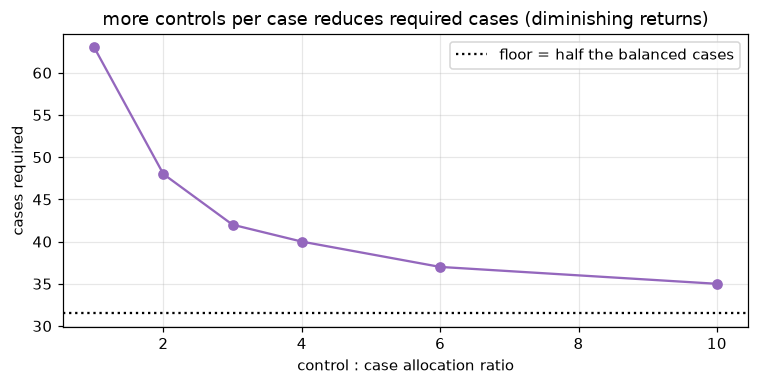

In [7]:
delta, sd = 1.5, 3.0
ratios = [1, 2, 3, 4, 6, 10]
print("control:case ratio  ->  cases / controls / total")
cases = []
for r in ratios:
    nc, nk = n_per_group_means(delta, sd, ratio=r)
    cases.append(nc)
    print(f"   {r:>2}:1   ->   {nc:>3} cases / {nk:>4} controls / {nc+nk:>4} total")

plt.figure(figsize=(7, 3.6))
plt.plot(ratios, cases, "o-", color="tab:purple")
plt.axhline(cases[0] / 2, color="k", ls=":", label="floor = half the balanced cases")
plt.xlabel("control : case allocation ratio"); plt.ylabel("cases required")
plt.title("more controls per case reduces required cases (diminishing returns)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 6. Monte-Carlo check: does the formula deliver the promised power?

A sanity check that builds intuition: take the $n$ the formula recommends for 80% power, then
**simulate** thousands of studies at that size, run an actual two-sample $t$-test on each, and count
how often we correctly reject $H_0$. The empirical rejection rate should land near 80%. (It is a touch
lower than the normal-theory value at small $n$ because the real test uses the heavier-tailed $t$
distribution — a good reason to round sample sizes **up**.)

In [8]:
def empirical_power_means(n_per_group, delta, sd, alpha=0.05, n_sims=4000):
    cases = rng.normal(delta, sd, size=(n_sims, n_per_group))
    controls = rng.normal(0.0, sd, size=(n_sims, n_per_group))
    _, pvals = stats.ttest_ind(cases, controls, axis=1)
    return np.mean(pvals < alpha)

delta, sd = 1.5, 3.0
n_case, _ = n_per_group_means(delta, sd, power=0.80)
analytic = power_means(n_case, delta / sd)
empirical = empirical_power_means(n_case, delta, sd)
print(f"recommended n per group = {n_case}")
print(f"analytic power (normal approx) = {analytic:.3f}")
print(f"empirical power (simulated t-tests) = {empirical:.3f}")

recommended n per group = 63
analytic power (normal approx) = 0.801
empirical power (simulated t-tests) = 0.793


## 7. Practical corrections

**Dropout / attrition.** Some enrolled participants are lost to follow-up or excluded. If a fraction
$f$ is expected to drop out, **inflate** enrollment so the *analyzable* sample still meets the target:
$$n_\text{enroll} = \frac{n_\text{analyzable}}{1 - f}.$$

**Multiple testing.** Testing many outcomes inflates the overall false-positive rate. A **Bonferroni**
correction splits $\alpha$ across $m$ tests ($\alpha' = \alpha/m$), which is stricter and therefore
**increases** the required sample size.

In [9]:
delta, sd = 1.5, 3.0
n_case, _ = n_per_group_means(delta, sd, power=0.80)

def inflate_for_dropout(n, f):
    return int(np.ceil(n / (1 - f)))

print("Dropout inflation (analyzable n per group = %d):" % n_case)
for f in [0.0, 0.10, 0.20, 0.30]:
    print(f"   {int(f*100):>2}% dropout  ->  enroll {inflate_for_dropout(n_case, f)} per group")

print("\nMultiple testing (Bonferroni) inflates required n:")
for m in [1, 5, 20]:
    nc, _ = n_per_group_means(delta, sd, alpha=0.05 / m, power=0.80)
    print(f"   {m:>2} tests  (alpha' = {0.05/m:.4f})  ->  {nc} per group")

Dropout inflation (analyzable n per group = 63):
    0% dropout  ->  enroll 63 per group
   10% dropout  ->  enroll 70 per group
   20% dropout  ->  enroll 79 per group
   30% dropout  ->  enroll 90 per group

Multiple testing (Bonferroni) inflates required n:
    1 tests  (alpha' = 0.0500)  ->  63 per group
    5 tests  (alpha' = 0.0100)  ->  94 per group
   20 tests  (alpha' = 0.0025)  ->  120 per group


## Takeaways

- **Plan $n$ before the study.** Power analysis is a design step; it protects against both missing a
  real effect (underpowered) and over-enrolling (wasteful/unethical).
- Required size is set by **four levers**: significance $\alpha$, power $1-\beta$, **effect size**
  (Cohen's $d$ for means; rate difference for proportions), and **variability** $\sigma$.
- $n$ scales as $1/d^2$ for means — **halving** the detectable effect roughly **quadruples** the
  cohort. Noisier measurements (larger $\sigma$) cost subjects too.
- **Binary** outcomes use the two-proportion formula; rates near 50% and small differences are the
  most demanding.
- **Unequal allocation** (more controls per case) lowers the number of hard-to-recruit cases, but
  never below half the balanced requirement.
- **Monte-Carlo simulation** reproduces the analytic power — always round **up**, and inflate for
  **dropout** and **multiple testing**.
- Pre-specify the assumed effect size from pilot data or the literature, and justify it: the whole
  calculation rests on that single, honestly-chosen number.